# LAB 12 — Artificial Neural Networks: The Multi-Layer Perceptron
## Student Information
- **Name: Krishna Lund**
- **Roll No: 023-24-0271**
- **Section: H**
- **Date: 23-11-2026**

**Dataset:** XOR and Breast Cancer Wisconsin (sklearn built-in)

In [15]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report
import tensorflow as tf
from tensorflow import keras

np.random.seed(42)
tf.random.set_seed(42)
X_xor = np.array([[0,0],[0,1],[1,0],[1,1]])
y_xor = np.array([0, 1, 1, 0])
print("Ready. TensorFlow", tf.__version__)


Ready. TensorFlow 2.21.0


## Part 0 — Key Concepts
Read the definitions table in the lab manual before starting.

## Part 1 — Why We Need Non-Linear Activations

### 1.1 Activation Functions and Their Slopes
**Task 1.1** — Plot the step and sigmoid functions and their derivatives (2×2 grid). Print each maximum derivative.

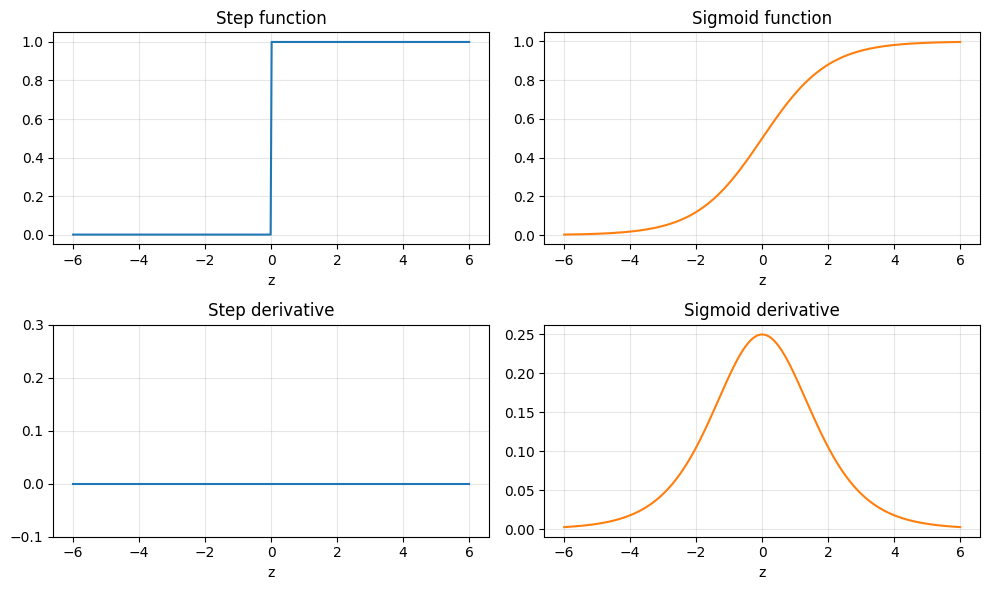

Max derivative of step    : 0.0
Max derivative of sigmoid : 0.25


In [16]:
# Task 1.1
def step(z):
    return np.where(z >= 0, 1.0, 0.0)

def step_deriv(z):
    return np.zeros_like(z, dtype=float)   # flat everywhere

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def sigmoid_deriv(z):
    s = sigmoid(z)
    return s * (1 - s)

z = np.linspace(-6, 6, 400)

fig, axes = plt.subplots(2, 2, figsize=(10, 6))
axes[0, 0].plot(z, step(z), color="tab:blue");            axes[0, 0].set_title("Step function")
axes[0, 1].plot(z, sigmoid(z), color="tab:orange");       axes[0, 1].set_title("Sigmoid function")
axes[1, 0].plot(z, step_deriv(z), color="tab:blue");      axes[1, 0].set_title("Step derivative")
axes[1, 1].plot(z, sigmoid_deriv(z), color="tab:orange"); axes[1, 1].set_title("Sigmoid derivative")
axes[1, 0].set_ylim(-0.1, 0.3)
for ax in axes.ravel():
    ax.grid(alpha=0.3); ax.set_xlabel("z")
plt.tight_layout()
plt.show()

print("Max derivative of step    :", step_deriv(z).max())
print("Max derivative of sigmoid :", round(sigmoid_deriv(z).max(), 4))

*Maximum derivative of step = 0.0; of sigmoid = 0.25 (at z = 0).
The sigmoid is smooth with a non-zero slope almost everywhere, so gradient descent has a direction to move in. The step function is flat, so its slope is 0.
Why the step function cannot be trained: because the derivative of constant is zero and the step derivative is 0 everywhere (except at the jump), so every gradient is 0 and the weights never change.*

### 1.2 Stacking Linear Layers Collapses
**Task 1.2** — Show that two linear layers equal one. Then add a sigmoid after the first layer and check again.

In [17]:
# Task 1.2
np.random.seed(42)
W1 = np.random.randn(2, 3)
b1 = np.random.randn(3)
W2 = np.random.randn(3, 1)
b2 = np.random.randn(1)
X  = np.random.randn(5, 2)

two_layer = (X @ W1 + b1) @ W2 + b2

W = W1 @ W2
b = b1 @ W2 + b2
one_layer = X @ W + b

print("Linear + Linear == single layer ?", np.allclose(two_layer, one_layer))
print("Collapsed W =", W.ravel().round(4), "| b =", b.round(4))

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

two_layer_sig = sigmoid(X @ W1 + b1) @ W2 + b2
print("Linear + Sigmoid + Linear == single layer ?", np.allclose(two_layer_sig, one_layer))
print("Max absolute difference with sigmoid:", np.abs(two_layer_sig - one_layer).max().round(4))

Linear + Linear == single layer ? True
Collapsed W = [0.0319 1.0439] | b = [0.9618]
Linear + Sigmoid + Linear == single layer ? False
Max absolute difference with sigmoid: 2.0569


*Without an activation, two layers gave the same output as one layer (allclose = True, W = [0.0319, 1.0439], b = 0.9618). With a sigmoid in between, the outputs became different (allclose = False, max difference = 2.0569). So extra layers only help when there is a non-linear activation between them.*

## Part 2 — Forward Pass: An MLP Solves XOR

### 2.1 Forward Pass Function
**Task 2.1** — Write `forward`. Use the step function with W1=[[1,1],[1,1]], b1=[−0.5,−1.5], W2=[[1],[−2]], b2=[−0.5]. Print the XOR table.

In [18]:
# Task 2.1
def step(z):
    return np.where(z >= 0, 1, 0)

def forward(X, W1, b1, W2, b2, f):
    h     = f(X @ W1 + b1)
    y_hat = f(h @ W2 + b2)
    return h, y_hat

W1_xor = np.array([[1, 1], [1, 1]])
b1_xor = np.array([-0.5, -1.5])
W2_xor = np.array([[1], [-2]])
b2_xor = np.array([-0.5])

h, y_hat = forward(X_xor, W1_xor, b1_xor, W2_xor, b2_xor, step)

print(" x1  x2 | h1  h2 | y_hat | true y")
print("-" * 36)
for i in range(4):
    print(f" {X_xor[i,0]}   {X_xor[i,1]}  |  {h[i,0]}   {h[i,1]} |   {y_hat[i,0]}   |   {y_xor[i]}")


 x1  x2 | h1  h2 | y_hat | true y
------------------------------------
 0   0  |  0   0 |   0   |   0
 0   1  |  1   0 |   1   |   1
 1   0  |  1   0 |   1   |   1
 1   1  |  1   1 |   0   |   0


*ŷ = 0, 1, 1, 0 matches the true XOR labels, so all four rows are correct.
h1 = OR gate (fires when x1 + x2 ≥ 0.5). h2 = AND gate (fires when x1 + x2 ≥ 1.5, only for (1,1)).
The output computes h1 − 2h2 − 0.5 ≥ 0, which means "OR but not AND" = XOR.*

### 2.2 The Hidden Layer Changes the Space
**Task 2.2** — Plot XOR in input space and in hidden space. Draw the line h₁ − 2h₂ − 0.5 = 0.

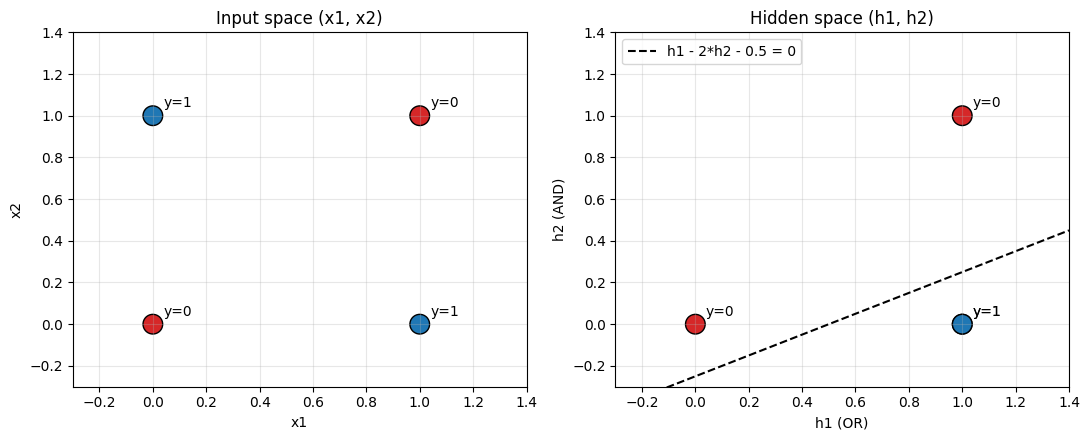

In [19]:
# Task 2.2
colors = ["tab:red" if c == 0 else "tab:blue" for c in y_xor]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].scatter(X_xor[:, 0], X_xor[:, 1], c=colors, s=200, edgecolors="k")
for (x1, x2), c in zip(X_xor, y_xor):
    axes[0].annotate(f"y={c}", (x1 + 0.04, x2 + 0.04))
axes[0].set_title("Input space (x1, x2)")
axes[0].set_xlabel("x1"); axes[0].set_ylabel("x2")
axes[0].set_xlim(-0.3, 1.4); axes[0].set_ylim(-0.3, 1.4); axes[0].grid(alpha=0.3)

axes[1].scatter(h[:, 0], h[:, 1], c=colors, s=200, edgecolors="k")
for (a, b_), c in zip(h, y_xor):
    axes[1].annotate(f"y={c}", (a + 0.04, b_ + 0.04))
h1_line = np.linspace(-0.3, 1.4, 100)
h2_line = (h1_line - 0.5) / 2
axes[1].plot(h1_line, h2_line, "k--", label="h1 - 2*h2 - 0.5 = 0")
axes[1].set_title("Hidden space (h1, h2)")
axes[1].set_xlabel("h1 (OR)"); axes[1].set_ylabel("h2 (AND)")
axes[1].set_xlim(-0.3, 1.4); axes[1].set_ylim(-0.3, 1.4)
axes[1].legend(loc="upper left"); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In the input space, the two classes sit on opposite diagonals, so no single straight line can separate them. After the hidden layer, both class-1 points land on (1, 0) and the class-0 points on (0, 0) and (1, 1), so the line h₁ − 2h₂ − 0.5 = 0 separates the classes with one straight line.

## Part 3 — Gradient Descent and the Learning Rate

**Task 3.1** — Minimise L(w)=(w−3)² from w=−4 for 30 steps with η = 0.01, 0.1, 0.9, 1.05. Plot w vs step.

eta = 0.01  | final w =      -0.8184 | final loss =        14.5801
eta = 0.1   | final w =       2.9913 | final loss =         0.0001
eta = 0.9   | final w =       2.9913 | final loss =         0.0001
eta = 1.05  | final w =    -119.1458 | final loss =     14919.6003


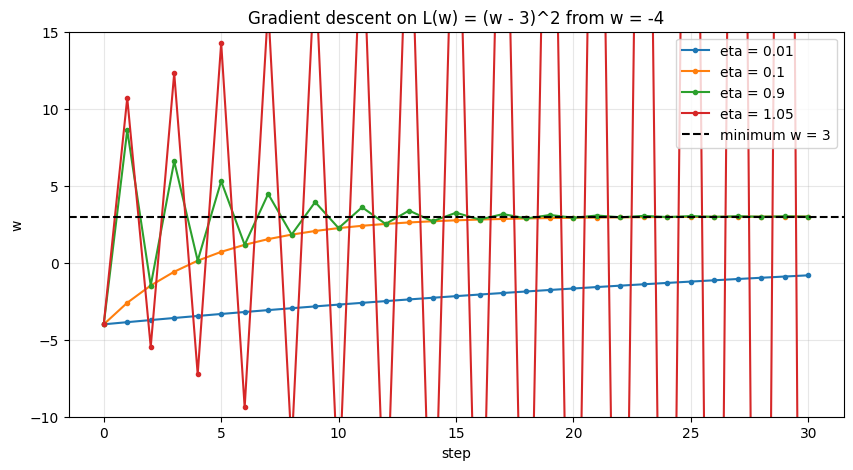

In [20]:
# Task 3.1
def gradient_descent(w0, eta, steps):
    w = w0
    ws = [w]
    for _ in range(steps):
        w = w - eta * 2 * (w - 3)
        ws.append(w)
    return ws

def loss(w):
    return (w - 3) ** 2

plt.figure(figsize=(10, 5))
for eta in [0.01, 0.1, 0.9, 1.05]:
    ws = gradient_descent(-4, eta, 30)
    plt.plot(ws, marker="o", markersize=3, label=f"eta = {eta}")
    print(f"eta = {eta:<5} | final w = {ws[-1]:>12.4f} | final loss = {loss(ws[-1]):>14.4f}")
plt.axhline(3, color="k", linestyle="--", label="minimum w = 3")
plt.ylim(-10, 15)
plt.xlabel("step"); plt.ylabel("w")
plt.title("Gradient descent on L(w) = (w - 3)^2 from w = -4")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

η = 0.01 (blue): too slow. After 30 steps w is still −0.82, far from 3 (loss 14.58).

η = 0.1 (orange): good. It moves smoothly and reaches w ≈ 2.99 (loss 0.0001).

η = 0.9 (green): zig-zags. It jumps from one side of w = 3 to the other, but the jumps get smaller and it settles at w ≈ 2.99.

η = 1.05 (red): blows up. The jumps get bigger every step and w ends at −119 (loss 14,919).

Each step multiplies the distance from w = 3 by (1 − 2η). If this number is smaller than 1 in size, gradient descent converges, and if it is bigger than 1, as it is for 1.05 (−1.1), it diverges.

## Part 4 — Backpropagation and the Chain Rule

### 4.1 Chain Rule for One Neuron
**Task 4.1** — x=[1,2], w=[0.5,−0.3], b=0.1, y=1. Chain-rule gradient, numerical check, one update with η=0.5.

In [21]:
# Task 4.1
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

x = np.array([1.0, 2.0]); w = np.array([0.5, -0.3]); b = 0.1; y = 1.0

def neuron_loss(w, b, x, y):
    return 0.5 * (y - sigmoid(w @ x + b)) ** 2

z = w @ x + b
a = sigmoid(z)
L = 0.5 * (y - a) ** 2
print(f"z = {z:.4f}, a = {a:.4f}, L = {L:.6f}")

dL_da = -(y - a)
da_dz = a * (1 - a)
dL_dw = dL_da * da_dz * x
dL_db = dL_da * da_dz
print("Chain rule  dL/dw =", dL_dw.round(6), " dL/db =", round(dL_db, 6))

eps = 0.0001
num_dw = np.zeros(2)
for i in range(2):
    wp, wm = w.copy(), w.copy()
    wp[i] += eps; wm[i] -= eps
    num_dw[i] = (neuron_loss(wp, b, x, y) - neuron_loss(wm, b, x, y)) / (2 * eps)
num_db = (neuron_loss(w, b + eps, x, y) - neuron_loss(w, b - eps, x, y)) / (2 * eps)
print("Numerical   dL/dw =", num_dw.round(6), " dL/db =", round(num_db, 6))
print("Match?", np.allclose(dL_dw, num_dw, atol=1e-6) and np.isclose(dL_db, num_db, atol=1e-6))

eta = 0.5
w_new = w - eta * dL_dw
b_new = b - eta * dL_db
L_new = neuron_loss(w_new, b_new, x, y)
print(f"\nNew w = {w_new.round(4)}, new b = {b_new:.4f}")
print(f"Loss before = {L:.6f}, after = {L_new:.6f}, went down? {L_new < L}")

z = 0.0000, a = 0.5000, L = 0.125000
Chain rule  dL/dw = [-0.125 -0.25 ]  dL/db = -0.125
Numerical   dL/dw = [-0.125 -0.25 ]  dL/db = -0.125
Match? True

New w = [ 0.5625 -0.175 ], new b = 0.1625
Loss before = 0.125000, after = 0.082960, went down? True


For x = [1, 2], w = [0.5, −0.3], b = 0.1, we get z = 0, so a = 0.5 and the loss is 0.125. The chain-rule gradients (dL/dw = [−0.125, −0.25], dL/db = −0.125) are exactly the same as the numerical check, so the gradient is correct. After one update with η = 0.5, w = [0.5625, −0.175] and b = 0.1625, and the loss went down from 0.125 to 0.08296. The gradients are negative, so the update pushes the weights up and makes a closer to the target y = 1.

### 4.2 Train an MLP on XOR With Backpropagation
**Task 4.2** — 2-4-1 sigmoid MLP, η=0.5, 5000 epochs, seed 42. Plot loss and print predictions.

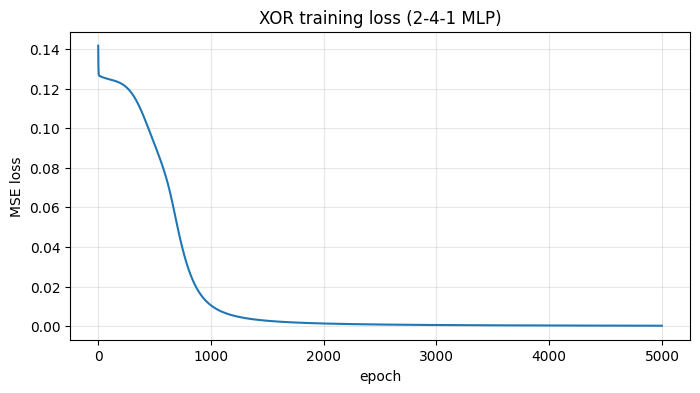

Loss at epoch 1/1000/5000: 0.14159 0.0106 0.000272
 x1  x2 | output A | rounded | true y
 0   0  |  0.0164  |    0    |   0
 0   1  |  0.9785  |    1    |   1
 1   0  |  0.9747  |    1    |   1
 1   1  |  0.0284  |    0    |   0


In [22]:
# Task 4.2
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

np.random.seed(42)
W1 = np.random.randn(2, 4)
b1 = np.zeros(4)
W2 = np.random.randn(4, 1)
b2 = np.zeros(1)

X = X_xor.astype(float)
y = y_xor.reshape(-1, 1).astype(float)

eta, epochs = 0.5, 5000
losses = []

for epoch in range(epochs):
    H = sigmoid(X @ W1 + b1)
    A = sigmoid(H @ W2 + b2)
    losses.append(np.mean(0.5 * (y - A) ** 2))

    dA  = (A - y) * A * (1 - A)
    dW2 = H.T @ dA
    db2 = dA.sum(axis=0)
    dH  = (dA @ W2.T) * H * (1 - H)
    dW1 = X.T @ dH
    db1 = dH.sum(axis=0)

    W1 -= eta * dW1; b1 -= eta * db1
    W2 -= eta * dW2; b2 -= eta * db2

plt.figure(figsize=(8, 4))
plt.plot(losses)
plt.xlabel("epoch"); plt.ylabel("MSE loss"); plt.title("XOR training loss (2-4-1 MLP)")
plt.grid(alpha=0.3); plt.show()

H = sigmoid(X @ W1 + b1)
A = sigmoid(H @ W2 + b2)
print("Loss at epoch 1/1000/5000:", round(losses[0], 5), round(losses[999], 5), round(losses[-1], 6))
print(" x1  x2 | output A | rounded | true y")
for i in range(4):
    print(f" {int(X[i,0])}   {int(X[i,1])}  |  {A[i,0]:.4f}  |    {int(np.round(A[i,0]))}    |   {int(y[i,0])}")


*The loss starts at 0.1416, stays on a slow plateau for a while, then drops quickly around epochs 300-1000 and flattens out. It reaches 0.0106 at epoch 1000 and 0.00027 at epoch 5000. The final outputs (0.016, 0.979, 0.975, 0.028) round to 0, 1, 1, 0, so all four predictions are correct. The network learned XOR by itself using backpropagation, without hand-picked weights.*

## Part 5 — MLP in Keras on Real Data

### 5.1 Train and Evaluate an MLP
**Task 5.1** — Breast Cancer: 80/20 split (stratify), StandardScaler, 30→16→8→1 MLP with sigmoid activations, 50 epochs. Summary, test accuracy, report, loss curves.

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,925 (7.52 KB)

 Trainable params: 641 (2.50 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,284 (5.02 KB)

Trainable parameters: 641

Test accuracy: 0.9649
              precision    recall  f1-score   support

   malignant       0.95      0.95      0.95        42
      benign       0.97      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114



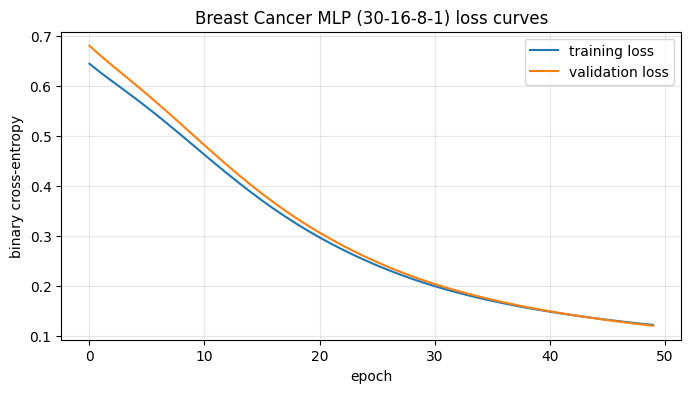

In [23]:
# Task 5.1
data = load_breast_cancer()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

np.random.seed(42)
tf.random.set_seed(42)
model = keras.Sequential([
    keras.Input(shape=(30,)),
    keras.layers.Dense(16, activation="sigmoid"),
    keras.layers.Dense(8, activation="sigmoid"),
    keras.layers.Dense(1, activation="sigmoid"),
])
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
history = model.fit(X_train, y_train, epochs=50, validation_split=0.2, verbose=0)

model.summary()
print("Trainable parameters:", model.count_params())

test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"\nTest accuracy: {test_acc:.4f}")
y_pred = (model.predict(X_test, verbose=0) > 0.5).astype(int).ravel()
print(classification_report(y_test, y_pred, target_names=data.target_names))

plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="training loss")
plt.plot(history.history["val_loss"], label="validation loss")
plt.xlabel("epoch"); plt.ylabel("binary cross-entropy")
plt.title("Breast Cancer MLP (30-16-8-1) loss curves")
plt.legend(); plt.grid(alpha=0.3); plt.show()

*The 30-16-8-1 network has 641 trainable parameters (496 + 136 + 9). The test accuracy is 96.49%, which means 110 out of 114 patients were classified correctly. For malignant, precision and recall are both 0.95, while for benign, precision and recall are both 0.97. In the loss plot, training and validation loss decrease together, showing that the model is learning without a clear sign of overfitting. Both curves are still decreasing at epoch 50, so training for more epochs could improve the model further.*

## Part 6 — Graded Questions
> Answer each question in a Markdown cell below using **your own numbers** from the lab.

**Q1 [4 marks]** — (a) Show W₂(W₁x + b₁) + b₂ = Wx + b and write W and b. (b) Why was the step function replaced by sigmoid for backpropagation?

*(a) W₂(W₁x + b₁) + b₂ = (W₂W₁)x + (W₂b₁ + b₂) = Wx + b, with W = W₂W₁ and b = W₂b₁ + b₂. In the row-vector form used in the lab this is W = W1 @ W2 and b = b1 @ W2 + b2. With my Task 1.2 numbers, W = [0.0319, 1.0439]ᵀ and b = 0.9618, and allclose printed True.*

*(b) In my Task 1.1 plot the step derivative is 0.0 everywhere, while the sigmoid slope is smooth with a maximum of 0.25 at z = 0. Backpropagation multiplies derivatives by the chain rule, so a zero slope makes the whole gradient 0 and no weight can be updated. Sigmoid has a non-zero slope, so gradient descent can move the weights, and it is non-linear, so the network does not collapse.*

**Q2 [4 marks]** — Forward pass by hand: W1=[[0.2,0.4],[0.6,−0.1]], b1=[0,0.1], W2=[[0.5],[−0.3]], b2=[0.2], x=[1,2], sigmoid everywhere. Compute h₁, h₂, ŷ (3 decimals) and check with your forward function.

In [24]:
# Q2
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

W1q = np.array([[0.2, 0.4], [0.6, -0.1]])
b1q = np.array([0.0, 0.1])
W2q = np.array([[0.5], [-0.3]])
b2q = np.array([0.2])
xq  = np.array([[1.0, 2.0]])

z1 = 1*0.2 + 2*0.6 + 0.0
z2 = 1*0.4 + 2*(-0.1) + 0.1
h1, h2 = sigmoid(z1), sigmoid(z2)
zo = h1*0.5 + h2*(-0.3) + 0.2
yh = sigmoid(zo)
print(f"z1 = {z1:.3f} -> h1 = {h1:.3f}")
print(f"z2 = {z2:.3f} -> h2 = {h2:.3f}")
print(f"z_out = {zo:.3f} -> y_hat = {yh:.3f}")

h_chk, y_chk = forward(xq, W1q, b1q, W2q, b2q, sigmoid)
print("\nforward() gives: h =", h_chk.round(3).ravel(), " y_hat =", y_chk.round(3).ravel())
print("Matches hand calculation?", np.allclose([h1, h2, yh], [*h_chk.ravel(), *y_chk.ravel()]))

z1 = 1.400 -> h1 = 0.802
z2 = 0.300 -> h2 = 0.574
z_out = 0.429 -> y_hat = 0.606

forward() gives: h = [0.802 0.574]  y_hat = [0.606]
Matches hand calculation? True


Using sigmoid everywhere with x = [1, 2]:

z₁ = 1·0.2 + 2·0.6 + 0 = 1.400, so h₁ = σ(1.4) = 0.802

z₂ = 1·0.4 + 2·(−0.1) + 0.1 = 0.300, so h₂ = σ(0.3) = 0.574

z = 0.802·0.5 + 0.574·(−0.3) + 0.2 = 0.429, so ŷ = σ(0.429) = 0.606

my forward() function gives h = [0.802, 0.574] and ŷ = 0.606, which is the same as my hand calculation (the code printed True).

**Q3 [6 marks]** — Task 4.1 neuron with y = 0: (a) ∂L/∂w₁, ∂L/∂w₂, ∂L/∂b; (b) one update with η=0.5, show the loss falls; (c) what happens with η=1.05 on a convex loss, and why?

In [25]:
# Q3
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

x = np.array([1.0, 2.0]); w = np.array([0.5, -0.3]); b = 0.1; y = 0.0

def L_fn(w, b):
    return 0.5 * (y - sigmoid(w @ x + b)) ** 2

a = sigmoid(w @ x + b)
L0 = L_fn(w, b)
print(f"a = {a:.4f}, L = {L0:.6f}")

# (a)
common = -(y - a) * a * (1 - a)
dw, db = common * x, common
print(f"(a) dL/dw1 = {dw[0]:.5f}, dL/dw2 = {dw[1]:.5f}, dL/db = {db:.5f}")

# (b)
eta = 0.5
w_new, b_new = w - eta * dw, b - eta * db
L1 = L_fn(w_new, b_new)
print(f"(b) new w = {w_new.round(5)}, new b = {b_new:.5f}")
print(f"    loss {L0:.6f} -> {L1:.6f}  (fell: {L1 < L0})")

# (c)
ws = gradient_descent(-4, 1.05, 30)
print("\n(c) eta = 1.05, w at steps 0-4:", [round(v, 3) for v in ws[:5]])
print("    |w - 3| at step 0, 10, 30:", [round(abs(ws[i] - 3), 2) for i in (0, 10, 30)])
print("    factor (1 - 2*eta) =", round(1 - 2 * 1.05, 2))

a = 0.5000, L = 0.125000
(a) dL/dw1 = 0.12500, dL/dw2 = 0.25000, dL/db = 0.12500
(b) new w = [ 0.4375 -0.425 ], new b = 0.03750
    loss 0.125000 -> 0.082960  (fell: True)

(c) eta = 1.05, w at steps 0-4: [-4, 10.7, -5.47, 12.317, -7.249]
    |w - 3| at step 0, 10, 30: [7, 18.16, 122.15]
    factor (1 - 2*eta) = -1.1


(a) Chain rule: ∂L/∂a = −(y − a) = 0.5 and ∂a/∂z = a(1 − a) = 0.25, so ∂L/∂z = 0.125. Then ∂L/∂w₁ = 0.125 × 1 = 0.125, ∂L/∂w₂ = 0.125 × 2 = 0.25 and ∂L/∂b = 0.125.

(b) With η = 0.5: w = [0.4375, −0.425], b = 0.0375, and the loss falls from 0.125 to 0.08296.

(c) With η = 1.05, each step multiplies (w − 3) by −1.1. Because 1.1 is bigger than 1, each step jumps past the minimum and lands farther away (|w − 3| grew from 7 to 122 in 30 steps). So gradient descent diverges even on a convex loss, because the learning rate is too large.

**Q4 [6 marks]** — Retrain Part 5.1 with one hidden layer of 4, 16, 64 neurons (100 epochs). Table of params, train acc, test acc; plot validation-loss curves; choose a size and comment on overfitting.

 Hidden neurons  Parameters  Train acc  Test acc  Final val loss
              4         129     0.9824    0.9561          0.1402
             16         513     0.9890    0.9649          0.0520
             64        2049     0.9868    0.9649          0.0496


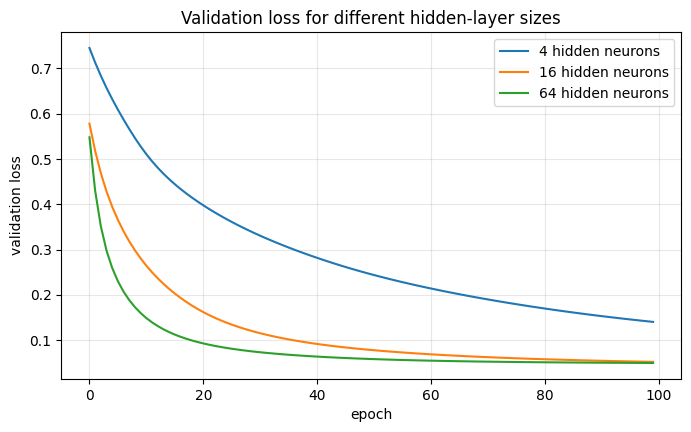

In [26]:
# Q4
import pandas as pd

sizes = [4, 16, 64]
rows, val_curves = [], {}

for n in sizes:
    np.random.seed(42)
    tf.random.set_seed(42)
    m = keras.Sequential([
        keras.Input(shape=(30,)),
        keras.layers.Dense(n, activation="sigmoid"),
        keras.layers.Dense(1, activation="sigmoid"),
    ])
    m.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    hist = m.fit(X_train, y_train, epochs=100, validation_split=0.2, verbose=0)

    rows.append({"Hidden neurons": n, "Parameters": m.count_params(),
                 "Train acc": round(m.evaluate(X_train, y_train, verbose=0)[1], 4),
                 "Test acc":  round(m.evaluate(X_test,  y_test,  verbose=0)[1], 4),
                 "Final val loss": round(hist.history["val_loss"][-1], 4)})
    val_curves[n] = hist.history["val_loss"]

print(pd.DataFrame(rows).to_string(index=False))

plt.figure(figsize=(8, 4.5))
for n in sizes:
    plt.plot(val_curves[n], label=f"{n} hidden neurons")
plt.xlabel("epoch"); plt.ylabel("validation loss")
plt.title("Validation loss for different hidden-layer sizes")
plt.legend(); plt.grid(alpha=0.3); plt.show()

The 4-neuron model has the highest final validation loss (0.1402), while the 16-neuron and 64-neuron models have lower validation losses of 0.0520 and 0.0496 respectively.

Choice: I would choose 16 neurons because it achieves 96.49% test accuracy, the same as the 64-neuron model, but uses significantly fewer parameters (513 compared to 2049). Its validation loss is also very close to the 64-neuron model.

Overfitting: The 64-neuron model shows a small difference between training accuracy (98.68%) and test accuracy (96.49%). However, its validation loss does not increase, so there is no strong evidence of overfitting from the validation-loss curve.

